# Úkol č. 1 - předzpracování dat a binární klasifikace

* Termíny jsou uvedeny na [courses.fit.cvut.cz/BI-ML1/homeworks/index.html](https://courses.fit.cvut.cz/BI-ML1/homeworks/index.html).
* Pokud odevzdáte úkol po prvním termínu ale před nejzazším termínem, budete penalizování -12 body, pozdější odevzdání je bez bodu.
* V rámci tohoto úkolu se musíte vypořádat s klasifikační úlohou s příznaky různých typů a s chybějícími hodnotami.
* Před tím, než na nich postavíte predikční model, je třeba je nějakým způsobem převést do číselné reprezentace.
    
> **Úkoly jsou zadány tak, aby Vám daly prostor pro invenci. Vymyslet _jak přesně_ budete úkol řešit, je důležitou součástí zadání a originalita či nápaditost bude také hodnocena!**

Využívejte buňky typu `Markdown` k vysvětlování Vašeho postupu. Za nepřehlednost budeme strhávat body.

## Zdroj dat

Budeme se zabývat predikcí přežití pasažérů Titaniku.
K dispozici máte trénovací data v souboru `data.csv` a data na vyhodnocení v souboru `evaluation.csv`.

#### Seznam příznaků:
* survived - zda pasažér přežil, 0 = Ne, 1 = Ano; **vysvětlovaná proměnná**, kterou chcete predikovat
* pclass - Třída lodního lístku, 1 = první, 2 = druhá, 3 = třetí
* name - jméno
* sex - pohlaví
* age - věk v letech
* sibsp	- počet sourozenců / manželů, manželek na palubě
* parch - počet rodičů / dětí na palubě
* ticket - číslo lodního lístku
* fare - cena lodního lístku
* cabin	- číslo kajuty
* embarked	- místo nalodění, C = Cherbourg, Q = Queenstown, S = Southampton
* home.dest - Bydliště/Cíl

## Pokyny k vypracování

**Body zadání**, za jejichž (poctivé) vypracování získáte **25 bodů**: 
  * V notebooku načtěte data ze souboru `data.csv`. Vhodným způsobem si je rozdělte na podmnožiny, které Vám poslouží pro trénování (trénovací), porovnávání modelů (validační) a následnou predikci výkonnosti finálního modelu (testovací).
    
  * Proveďte základní předzpracování dat:
    * Projděte si jednotlivé příznaky a transformujte je do vhodné podoby pro použití ve vybraném klasifikačním modelu.
    * Podle potřeby si můžete vytvářet nové příznaky (na základě existujících), například tedy můžete vytvořit příznak měřící délku jména atp.
    * Některé příznaky můžete také úplně zahodit.
    * Nějakým způsobem (klidně triviálním) se vypořádejte s chybějícími hodnotami. Není potřeba používat sofistikované metody. _Hlavně pozor na metodické chyby!_
    * Můžete využívat i vizualizace a vše stručně ale náležitě komentujte.

  
  * Na připravená data postupně aplikujte **rozhodovací strom** a **metodu nejbližších sousedů**, přičemž pro každý z těchto modelů:
    * Okomentujte vhodnost daného modelu pro daný typ úlohy.
    * Vyberte si hlavní hyperparametry k ladění a najděte jejich nejlepší hodnoty.
    * Pro model s nejlepšími hodnotami hyperparametrů spočtěte F1 skóre, nakreslete ROC křivku a určete AUC. _Pozor na metodické chyby!_
    * Získané výsledky vždy řádně okomentujte.

        
  * Ze všech zkoušených možností v předchozím kroku vyberte finální model (jednoznačně popište o který konkrétně jde) a správně odhadněte, jakou **přesnost** můžete očekávat na nových datech, která jste doposud neměli k dispozici. _Pozor na metodické chyby!_
    
  * Nakonec načtěte vyhodnocovací data ze souboru `evaluation.csv`. Pomocí finálního modelu napočítejte predikce pro tyto data (vysvětlovaná proměnná v nich již není). Vytvořte soubor `results.csv`, ve kterém získané predikce uložíte do sloupce **survived** a identifikátory do sloupce **ID** (dodržte názvy sloupců!). Tento soubor též odevzdejte (uložte do repozitáře vedle notebooku).

      * Snažte se vše udělat tak, aby přesnost odevzdaných predikcí na vyhodocovacím datasetu byla alespoň **75%**. Pokud bude menší, přijdete o **3 body**.
      * Ukázka, jak by mělo vypadat prvních několik řádků souboru `results.csv` (obecně s jinými hodnotami survived):
  
```
ID,survived
1000,0
1001,1
...
```

## Poznámky k odevzdání

  * Řiďte se pokyny ze stránky https://courses.fit.cvut.cz/BI-ML1/homeworks/index.html.
  * Vytvořte i csv soubor `results.csv` s predikcemi a uložte ho v rámci projektu vedle ipython notebooku.

## 0. Importing Necessary Libraries
In this step, we import libraries which we will use during solving this homework.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, ParameterGrid
from sklearn.metrics import f1_score, roc_curve, auc, classification_report, confusion_matrix, roc_auc_score
import sklearn.metrics as metrics
import warnings
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer

rd_seed = 333

## 1. Data Preprocessing
We load the dataset and perform a basic analysis to understand its structure.

In [2]:
data = pd.read_csv('data.csv')
display(data.shape)
display(data.head())
display(data.info())
display(data.describe())
display(data.nunique())

(1000, 13)

,ID,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,home.dest
0,0,0,2,"Baimbrigge, Mr. Charles Robert",male,23.0,0,0,C.A. 31030,10.5000,NaN,S,Guernsey
1,1,0,3,"Aronsson, Mr. Ernst Axel Algot",male,24.0,0,0,349911,7.7750,NaN,S,"Sweden Joliet, IL"
2,2,0,3,"Novel, Mr. Mansouer",male,28.5,0,0,2697,7.2292,NaN,C,NaN
3,3,0,3,"Osen, Mr. Olaf Elon",male,16.0,0,0,7534,9.2167,NaN,S,NaN
4,4,1,2,"Navratil, Master. Michel M",male,3.0,1,1,230080,26.0000,F2,S,"Nice, France"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   survived   1000 non-null   int64  
 2   pclass     1000 non-null   int64  
 3   name       1000 non-null   object 
 4   sex        1000 non-null   object 
 5   age        796 non-null    float64
 6   sibsp      1000 non-null   int64  
 7   parch      1000 non-null   int64  
 8   ticket     1000 non-null   object 
 9   fare       1000 non-null   float64
 10  cabin      225 non-null    object 
 11  embarked   1000 non-null   object 
 12  home.dest  573 non-null    object 
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB


None

,ID,survived,pclass,age,sibsp,parch,fare
count,1000.000000,1000.000000,1000.000000,796.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,0.373000,2.309000,29.894996,0.522000,0.390000,32.356224
std,288.819436,0.483844,0.835594,14.580693,1.092112,0.877879,50.053812
min,0.000000,0.000000,1.000000,0.166700,0.000000,0.000000,0.000000
25%,249.750000,0.000000,2.000000,21.000000,0.000000,0.000000,7.895800
50%,499.500000,0.000000,3.000000,28.000000,0.000000,0.000000,14.458300
75%,749.250000,1.000000,3.000000,39.000000,1.000000,0.000000,31.068750
max,999.000000,1.000000,3.000000,80.000000,8.000000,9.000000,512.329200


ID           1000
survived        2
pclass          3
name          998
sex             2
age            93
sibsp           7
parch           8
ticket        747
fare          260
cabin         155
embarked        3
home.dest     308
dtype: int64

Dropped irrelevant columns, converted `sex` to numerical (0, 1), and encoded `embarked` as numbers(0, 1, 2).

In [3]:
data = data.drop(['name', 'ticket', 'cabin', 'home.dest', 'ID'], axis=1)

data['sex'] = data['sex'].map({'male': 0, 'female': 1})

data['embarked'] = data['embarked'].map({'C': 0, 'Q': 1, 'S': 2})

display(data.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,2,0,23.0,0,0,10.5000,2
1,0,3,0,24.0,0,0,7.7750,2
2,0,3,0,28.5,0,0,7.2292,0
3,0,3,0,16.0,0,0,9.2167,2
4,1,2,0,3.0,1,1,26.0000,2


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  1000 non-null   int64  
 1   pclass    1000 non-null   int64  
 2   sex       1000 non-null   int64  
 3   age       796 non-null    float64
 4   sibsp     1000 non-null   int64  
 5   parch     1000 non-null   int64  
 6   fare      1000 non-null   float64
 7   embarked  1000 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Dividing data
Let's divide out data as 60% training data, 20% testing and 20% validation  data.

In [5]:
Xdata = data.drop("survived", axis = 1)
ydata = data['survived']

Xtrain, Xtest, ytrain, ytest = train_test_split(Xdata, ydata, test_size=0.4, random_state=rd_seed) 
display(Xtrain.shape)
display(ytrain.shape)
display(Xtest.shape)
display(ytest.shape)

(600, 7)

(600,)

(400, 7)

(400,)

In [6]:
Xval, Xtest, yval, ytest = train_test_split(Xtest, ytest, test_size=0.5, random_state=rd_seed) 
display(Xval.shape)
display(yval.shape)
display(Xtest.shape)
display(ytest.shape)

(200, 7)

(200,)

(200, 7)

(200,)

### Null values

Lets check what null values are left.

In [7]:
data.isnull().sum()

survived      0
pclass        0
sex           0
age         204
sibsp         0
parch         0
fare          0
embarked      0
dtype: int64

We have left only age column, that have null values in it and now lets fix it.

In [8]:
XtrainMedian = Xtrain['age'].median()

Xtrain['age'] = Xtrain['age'].fillna(XtrainMedian)
Xval['age'] = Xval['age'].fillna(XtrainMedian)
Xtest['age'] = Xtest['age'].fillna(XtrainMedian)

In [9]:
display(Xtrain.isnull().sum())
display(Xtest.isnull().sum())
display(Xval.isnull().sum())

pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

In [10]:
Xtrain.info()
Xtest.info()
Xval.info()

<class 'pandas.core.frame.DataFrame'>
Index: 600 entries, 468 to 780
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    600 non-null    int64  
 1   sex       600 non-null    int64  
 2   age       600 non-null    float64
 3   sibsp     600 non-null    int64  
 4   parch     600 non-null    int64  
 5   fare      600 non-null    float64
 6   embarked  600 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 37.5 KB
<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 792 to 243
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    200 non-null    int64  
 1   sex       200 non-null    int64  
 2   age       200 non-null    float64
 3   sibsp     200 non-null    int64  
 4   parch     200 non-null    int64  
 5   fare      200 non-null    float64
 6   embarked  200 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 12

Now we have done with null values.

## 2. Decision Tree

### Implementation

Lets implement our desicion tree and train it on train data.

In [11]:
clf = DecisionTreeClassifier(max_depth = 1)
clf.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 1,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

Teaching model using fit() function.

In [12]:
clf.fit(Xtrain, ytrain)

DecisionTreeClassifier(max_depth=1)

Iterate over all parameter combinations for Decision Tree, training on each and recording accuracy for training and validation sets, min_depth = 1, max_depth = 30


In [13]:
param_grid = {
    'max_depth': range(1,30), 
    'criterion': ['entropy', 'gini']
}
param_comb = ParameterGrid(param_grid)
val_acc = []
train_acc = []
for params in param_comb:
    clf = DecisionTreeClassifier(max_depth=params['max_depth'], criterion=params['criterion'], random_state = 42)
    clf.fit(Xtrain, ytrain)
    train_acc.append(metrics.accuracy_score(ytrain, clf.predict(Xtrain)))
    val_acc.append(metrics.accuracy_score(yval, clf.predict(Xval)))

Drawing a plot wtih training and validating accuracies

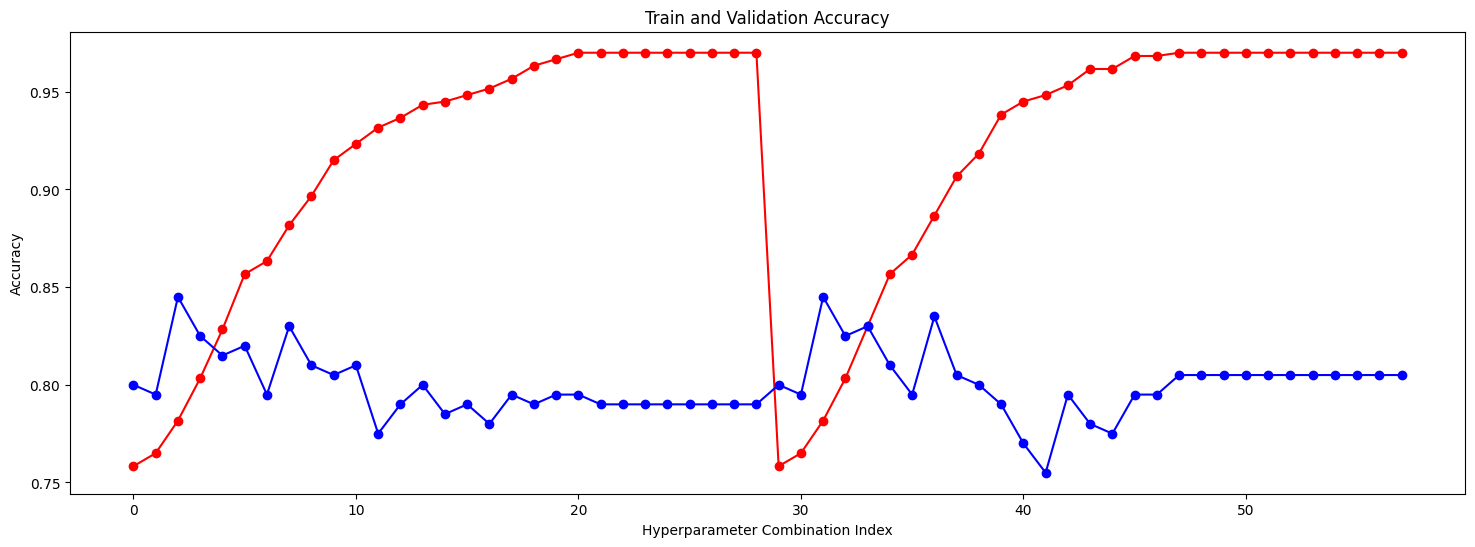

In [14]:
plt.figure(figsize=(18,6))
plt.plot(train_acc, 'or-')
plt.plot(val_acc, 'ob-')


plt.xlabel('Hyperparameter Combination Index')
plt.ylabel('Accuracy')
plt.title('Train and Validation Accuracy')
plt.show()

Lets print results

In [15]:
clf = DecisionTreeClassifier(**param_comb[np.argmax(val_acc)])
clf.fit(Xtrain, ytrain)
print('accuracy score (train): {0:.6f}'.format(metrics.accuracy_score(ytrain, clf.predict(Xtrain))))
print('accuracy score (validation): {0:.6f}'.format(metrics.accuracy_score(yval, clf.predict(Xval))))
print('accuracy score (test): {0:.6f}'.format(metrics.accuracy_score(ytest, clf.predict(Xtest))))

accuracy score (train): 0.781667
accuracy score (validation): 0.845000
accuracy score (test): 0.855000


The model shows good generalization with high accuracy on validation (84.5%) and test sets (85.5%). Training accuracy (78.2%) is a bit lower, which means there’s minimal overfitting. Consistent results across splits suggest the model is well-tuned.

## 3. KNN

We need to prepare data subsets for KNN. For this, we perform min-max normalization.

In [16]:
scaler = MinMaxScaler()
scaler.fit(Xtrain)

Xtrain_scaled = scaler.transform(Xtrain)
Xval_scaled = scaler.transform(Xval)
Xtest_scaled = scaler.transform(Xtest)

We iterate over all hyperparameter combinations for KNN, train the model, and store accuracy for training and validation sets; then, we select the parameters with the highest validation accuracy.

In [17]:
val_acc = []
train_acc = []

param_grid = {
    'n_neighbors': range(1, 20), 
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

param_comb = ParameterGrid(param_grid)
for params in param_comb:
    knn = KNeighborsClassifier(**params)
    knn.fit(Xtrain_scaled, ytrain)
    train_acc.append(metrics.accuracy_score(ytrain, knn.predict(Xtrain_scaled)))
    val_acc.append(metrics.accuracy_score(yval, knn.predict(Xval_scaled)))

best_val_index = np.argmax(val_acc)
best_params = param_comb[best_val_index]

We create combined plots showing KNN accuracy for each metric type across different n_neighbors values and weights. Each plot compares training and validation accuracy, making it easy to observe performance changes across hyperparameters.

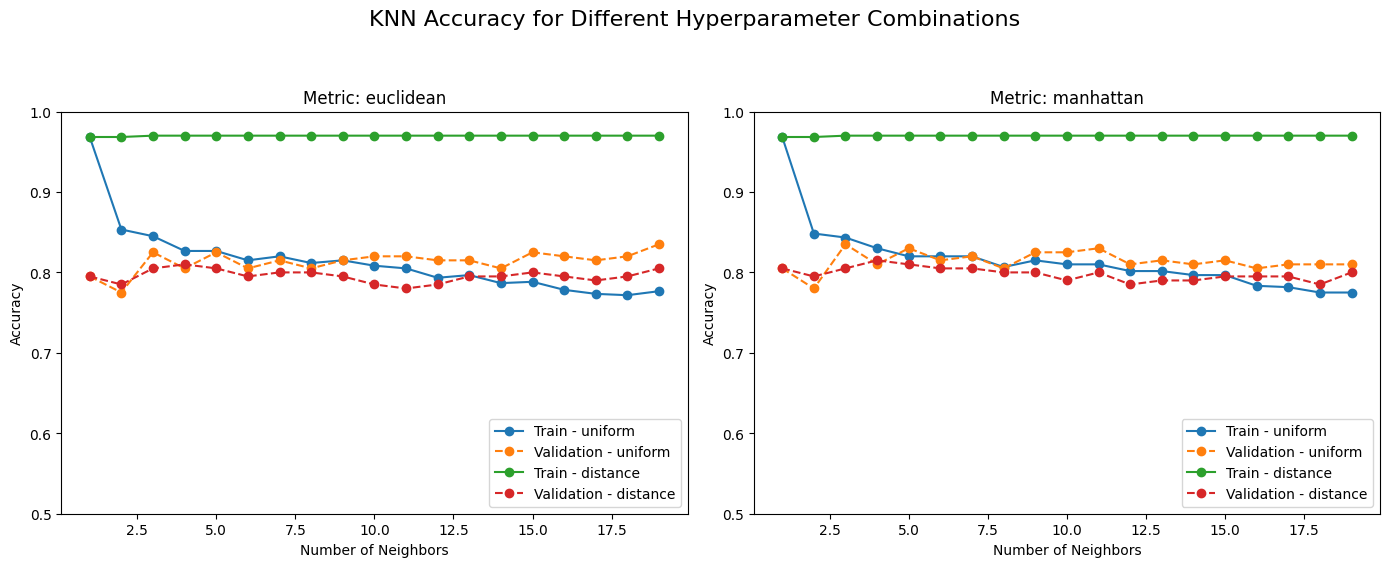

In [18]:
plt.figure(figsize=(14, 10))
plt.suptitle('KNN Accuracy for Different Hyperparameter Combinations', fontsize=16)

results_df = pd.DataFrame({
    'n_neighbors': [params['n_neighbors'] for params in param_comb],
    'weights': [params['weights'] for params in param_comb],
    'metric': [params['metric'] for params in param_comb],
    'train_acc': train_acc,
    'val_acc': val_acc
})

for i, metric in enumerate(results_df['metric'].unique(), 1):
    plt.subplot(2, 2, i)  

    for weight in results_df['weights'].unique():
        subset = results_df[(results_df['metric'] == metric) & (results_df['weights'] == weight)]

        plt.plot(subset['n_neighbors'], subset['train_acc'], label=f'Train - {weight}', marker='o', linestyle='-')
        plt.plot(subset['n_neighbors'], subset['val_acc'], label=f'Validation - {weight}', marker='o', linestyle='--')

    plt.title(f'Metric: {metric}')
    plt.xlabel('Number of Neighbors')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim(0.5, 1)  

plt.tight_layout(rect=[0, 0, 1, 0.95])  
plt.show()


We just printed the results to evaluate model performance on the training, validation, and test sets.

In [19]:
best_params = param_comb[best_val_index]
knn = KNeighborsClassifier(**best_params)
knn.fit(Xtrain_scaled, ytrain)
print('accuracy score (train): {0:.6f}'.format(metrics.accuracy_score(ytrain, knn.predict(Xtrain_scaled))))
print('accuracy score (validation): {0:.6f}'.format(metrics.accuracy_score(yval, knn.predict(Xval_scaled))))
print('accuracy score (test): {0:.6f}'.format(metrics.accuracy_score(ytest, knn.predict(Xtest_scaled))))

accuracy score (train): 0.776667
accuracy score (validation): 0.835000
accuracy score (test): 0.835000


The model shows strong generalization with high validation and test accuracy (83.5%), slightly lower training accuracy (77.7%) indicating minimal overfitting, and consistent performance across splits, confirming it’s well-suited for new data.

## 4. F1 score, plotting the ROC curve, and determining AUC

We calculated the F1 score on the validation set for  the Decision Tree and KNN models to evaluate their performance. This score helps measure the balance between precision and recall, giving an overall assessment of model effectiveness on the validation data.

In [20]:
y_pred_clf = clf.predict(Xval)  
f1_tree = f1_score(yval, y_pred_clf)  

y_pred_knn = knn.predict(Xval_scaled)
f1_knn = f1_score(yval, y_pred_knn)
print(f"Decision Tree - F1 Score (test): {f1_tree:.4f}")
print(f"KNN - F1 Score (test): {f1_knn:.4f}")


Decision Tree - F1 Score (test): 0.7770
KNN - F1 Score (test): 0.7317


We calculate the Area Under the Curve (AUC) for the Decision Tree and KNN models on the test set. A higher AUC indicates better model performance.

In [21]:
y_pred_proba_tree = clf.predict_proba(Xtest)[:, 1]
y_pred_proba_knn = knn.predict_proba(Xtest_scaled)[:, 1]

fpr_tree, tpr_tree, _ = roc_curve(ytest, y_pred_proba_tree)
roc_auc_tree = auc(fpr_tree, tpr_tree)

print(f"Decision Tree - AUC: {roc_auc_tree:.4f}")

fpr_knn, tpr_knn, _ = roc_curve(ytest, y_pred_proba_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)

print(f"KNN - AUC: {roc_auc_knn:.4f}")

Decision Tree - AUC: 0.8965
KNN - AUC: 0.8958


We plot the ROC curves. This comparison helps us understand the trade-off between true positive rate and false positive rate for each model.

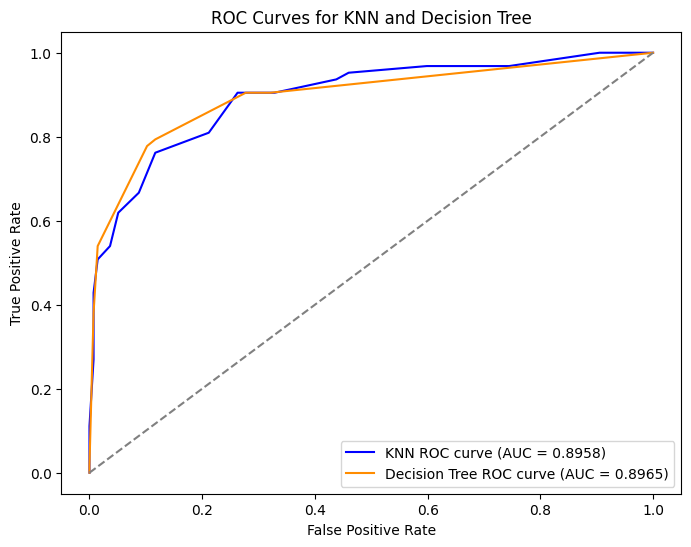

In [22]:
fpr_tree, tpr_tree, _ = roc_curve(ytest, y_pred_proba_tree)
auc_tree = roc_auc_score(ytest, y_pred_proba_tree)

fpr_knn, tpr_knn, _ = roc_curve(ytest, y_pred_proba_knn)
auc_knn = roc_auc_score(ytest, y_pred_proba_knn)


plt.figure(figsize=(8, 6))
plt.plot(fpr_knn, tpr_knn, color='blue', label=f'KNN ROC curve (AUC = {auc_knn:.4f})')
plt.plot(fpr_tree, tpr_tree, color='darkorange', label=f'Decision Tree ROC curve (AUC = {auc_tree:.4f})')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--') 

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for KNN and Decision Tree')
plt.legend(loc="lower right")
plt.show()

Both models perform similarly in terms of AUC, but the Decision Tree has a higher F1 Score, making it the better choice for this classification task.

## 5. Evaluation

In [23]:
# We read a data
evaluation_data = pd.read_csv('evaluation.csv')

# Preserve the ID column for final results
ids = evaluation_data['ID']

# Preprocess evaluation data (same steps as the training data)
evaluation_data = evaluation_data.drop(['name', 'ticket', 'cabin', 'home.dest', 'ID'], axis=1)
evaluation_data['sex'] = evaluation_data['sex'].map({'male': 0, 'female': 1})
evaluation_data['embarked'] = evaluation_data['embarked'].map({'C': 0, 'Q': 1, 'S': 2})

# Fill missing values with the median for each column
imputer = SimpleImputer(strategy='median')
evaluation_data = pd.DataFrame(imputer.fit_transform(evaluation_data), columns=evaluation_data.columns)

# Scale the data
evaluation_data_scaled = scaler.transform(evaluation_data)

# Use the final model (e.g., KNN) to make predictions
evaluation_predictions = knn.predict(evaluation_data_scaled)

# Create DataFrame for saving results
results_df = pd.DataFrame({
    'ID': ids,  # Use original IDs
    'survived': evaluation_predictions
})

# Save results to CSV
results_df.to_csv('results.csv', index=False)

Results saved to results.csv